In [2]:
!pip install statsbombpy

from statsbombpy import sb
comps = sb.competitions()
print(comps[["competition_id", "season_id", "competition_name", "season_name"]])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.8/63.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 5.7 MB/s eta 0:00:00
    competition_id  season_id        competition_name season_name
0                9        281           1. Bundesliga   2023/2024
1                9         27           1. Bundesliga   2015/2016
2             1267        107  African Cup of Nations        2023
3               16          4        Champions League   2018/2019
4               16          1        Champions League   2017/2018
..             ...        ...                     ...         ...
75              35         75      UEFA Europa League   1988/1989
76              53        315       UEFA Women's Euro        2025
77              53        106       UEFA Women's Euro        2022
78              72        107       Women's World Cup        2023
79              72         30       Wo

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


In [3]:
comps[comps["competition_name"].str.contains("World Cup|Euro|Copa", case=False)]

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
21,223,282,South America,Copa America,male,False,True,2024,2026-05-13T12:24:48.807600,None,None,2026-05-13T12:24:48.807600
22,87,84,Spain,Copa del Rey,male,False,False,1983/1984,2024-02-13T01:54:12.946985,2021-06-13T16:17:31.694,None,2024-02-13T01:54:12.946985
23,87,268,Spain,Copa del Rey,male,False,False,1982/1983,2024-02-13T14:19:57.954551,None,None,2024-02-13T14:19:57.954551
24,87,279,Spain,Copa del Rey,male,False,False,1977/1978,2024-02-13T14:26:19.978418,None,None,2024-02-13T14:26:19.978418
29,1470,274,International,FIFA U20 World Cup,male,True,True,1979,2024-02-13T14:20:59.825440,None,None,2024-02-13T14:20:59.825440
30,43,106,International,FIFA World Cup,male,False,True,2022,2026-05-04T01:48:57.914346,2026-05-04T01:53:40.309717,2026-05-04T01:53:40.309717,2026-05-04T01:48:57.914346
31,43,3,International,FIFA World Cup,male,False,True,2018,2026-05-15T15:48:12.789440,2021-06-13T16:17:31.694,None,2026-05-15T15:48:12.789440
32,43,55,International,FIFA World Cup,male,False,True,1990,2023-06-28T10:58:20.137929,2021-06-12T16:17:31.694,None,2023-06-28T10:58:20.137929
33,43,54,International,FIFA World Cup,male,False,True,1986,2026-05-04T01:30:23.212111,2021-06-13T16:17:31.694,None,2026-05-04T01:30:23.212111
34,43,51,International,FIFA World Cup,male,False,True,1974,2026-05-15T02:20:43.439689,2021-06-13T16:17:31.694,None,2026-05-15T02:20:43.439689


Pull the data using the IDs directly

In [4]:
import pandas as pd
from statsbombpy import sb

tournaments = {
    "World Cup 2018": (43, 3),
    "Euro 2020": (55, 43),
    "Copa America 2024": (223, 282),
    "Euro 2024": (55, 282),
    "World Cup 2022": (43, 106),
}

frames = []
for name, (cid, sid) in tournaments.items():
    matches = sb.matches(competition_id=cid, season_id=sid)
    print(name, len(matches), "matches")
    for mid in matches["match_id"]:
        ev = sb.events(match_id=mid)
        s = ev[ev["type"] == "Shot"].copy()
        s["match_id"] = mid
        s["tournament"] = name
        frames.append(s)

shots = pd.concat(frames, ignore_index=True)
shots.to_pickle("shots_tournaments.pkl")
print(shots["tournament"].value_counts())

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


World Cup 2018 64 matches


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

Euro 2020 51 matches


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

...

Euro 2024 51 matches


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

World Cup 2022 64 matches


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

tournament
World Cup 2018       1706
World Cup 2022       1494
Euro 2024            1340
Euro 2020            1289
Copa America 2024     790
Name: count, dtype: int64


Step 1: Clean the data and build features

In [5]:
import numpy as np
import pandas as pd

shots = pd.read_pickle("shots_tournaments.pkl")

# Remove penalties and shootouts (they behave differently)
shots = shots[(shots["shot_type"] != "Penalty") & (shots["period"] != 5)].copy()

shots["x"] = shots["location"].apply(lambda l: l[0])
shots["y"] = shots["location"].apply(lambda l: l[1])

dx = 120 - shots["x"]
dy = (shots["y"] - 40).abs()
shots["distance"] = np.sqrt(dx**2 + dy**2)
shots["angle"] = np.arctan2(8 * dx, dx**2 + dy**2 - 16)
shots["angle"] = np.where(shots["angle"] < 0, shots["angle"] + np.pi, shots["angle"])

shots["is_header"] = (shots["shot_body_part"] == "Head").astype(int)
shots["goal"] = (shots["shot_outcome"] == "Goal").astype(int)

df = shots[["match_id", "tournament", "x", "y", "distance", "angle",
            "is_header", "shot_type", "play_pattern", "goal",
            "shot_statsbomb_xg"]].copy()

print(df.groupby("tournament")["goal"].agg(["count", "sum", "mean"]))

                   count  sum      mean
tournament                             
Copa America 2024    741   63  0.085020
Euro 2020           1234  122  0.098865
Euro 2024           1304   98  0.075153
World Cup 2018      1638  135  0.082418
World Cup 2022      1430  152  0.106294


Step 2: Make 3 exploratory visuals

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 4.6 MB/s eta 0:00:00
              mean  count
distance                 
(0, 6]    0.398990    198
(6, 12]   0.156792   1384
(12, 18]  0.101307   1530
(18, 24]  0.048063   1394
(24, 30]  0.033388   1228
(30, 40]  0.016100    559


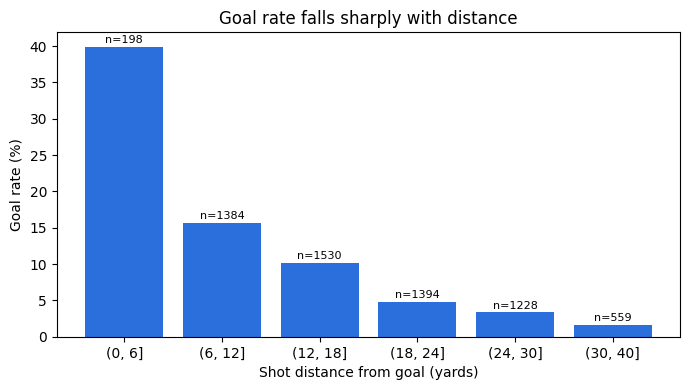

In [6]:
!pip install mplsoccer

import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch
import pandas as pd

# ---------- 1. Goal rate by distance bucket ----------
bins = [0, 6, 12, 18, 24, 30, 40]
bucket = pd.cut(df["distance"], bins)

summary = df.groupby(bucket, observed=True)["goal"].agg(["mean", "count"])
print(summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary.index.astype(str), summary["mean"] * 100, color="#2a6fdb")
for i, (rate, n) in enumerate(zip(summary["mean"], summary["count"])):
    ax.text(i, rate * 100 + 0.5, f"n={n}", ha="center", fontsize=8)
ax.set_xlabel("Shot distance from goal (yards)")
ax.set_ylabel("Goal rate (%)")
ax.set_title("Goal rate falls sharply with distance")
plt.tight_layout()
plt.savefig("viz1_goal_rate_by_distance.png", dpi=150)
plt.show()

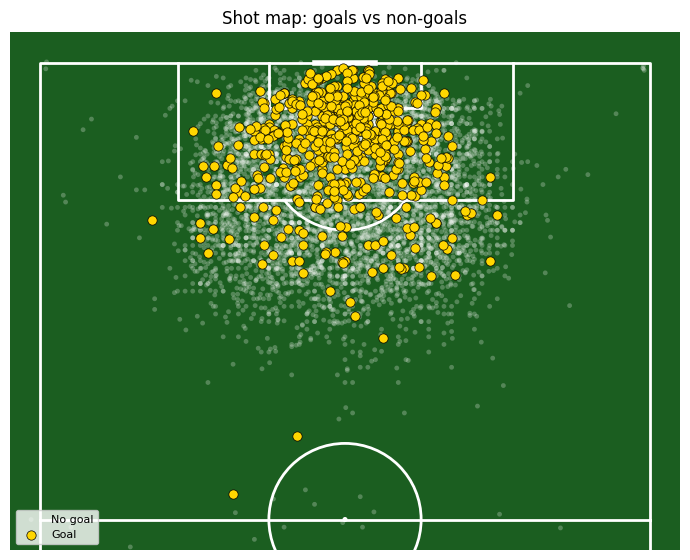

In [7]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color="#1b5e20", line_color="white")
fig, ax = pitch.draw(figsize=(7, 6))

misses = df[df["goal"] == 0]
goals = df[df["goal"] == 1]

pitch.scatter(misses["x"], misses["y"], s=12, c="white",
              alpha=0.25, edgecolors="none", ax=ax, label="No goal")
pitch.scatter(goals["x"], goals["y"], s=45, c="#ffd600",
              edgecolors="black", linewidth=0.5, ax=ax, label="Goal")

ax.legend(loc="lower left", fontsize=8)
ax.set_title("Shot map: goals vs non-goals", color="black")
plt.savefig("viz2_shot_map.png", dpi=150, bbox_inches="tight")
plt.show()

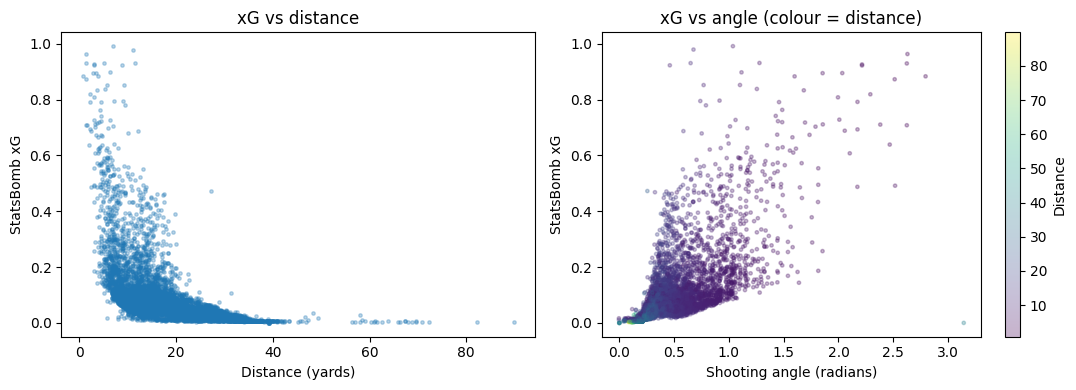

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(df["distance"], df["shot_statsbomb_xg"], s=6, alpha=0.3)
axes[0].set_xlabel("Distance (yards)")
axes[0].set_ylabel("StatsBomb xG")
axes[0].set_title("xG vs distance")

sc = axes[1].scatter(df["angle"], df["shot_statsbomb_xg"], s=6,
                     alpha=0.3, c=df["distance"], cmap="viridis")
axes[1].set_xlabel("Shooting angle (radians)")
axes[1].set_ylabel("StatsBomb xG")
axes[1].set_title("xG vs angle (colour = distance)")
fig.colorbar(sc, ax=axes[1], label="Distance")

plt.tight_layout()
plt.savefig("viz3_features_vs_statsbomb_xg.png", dpi=150)
plt.show()

Step 3: Train the baseline with the World Cup 2022 held out

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

feats = ["distance", "angle", "is_header"]
train = df[df["tournament"] != "World Cup 2022"]
test  = df[df["tournament"] == "World Cup 2022"]

model = LogisticRegression(max_iter=1000)
model.fit(train[feats], train["goal"])
p = model.predict_proba(test[feats])[:, 1]

print("Your model  log loss:", log_loss(test["goal"], p))
print("StatsBomb   log loss:", log_loss(test["goal"], test["shot_statsbomb_xg"]))
print("Your model  AUC     :", roc_auc_score(test["goal"], p))
print("StatsBomb   AUC     :", roc_auc_score(test["goal"], test["shot_statsbomb_xg"]))
print(dict(zip(feats, model.coef_[0])))

Your model  log loss: 0.289634271100424
StatsBomb   log loss: 0.2665049367538332
Your model  AUC     : 0.779597541388683
StatsBomb   AUC     : 0.8147753479943991
{'distance': np.float64(-0.08689955354251881), 'angle': np.float64(1.273868209774149), 'is_header': np.float64(-1.0266105862775288)}


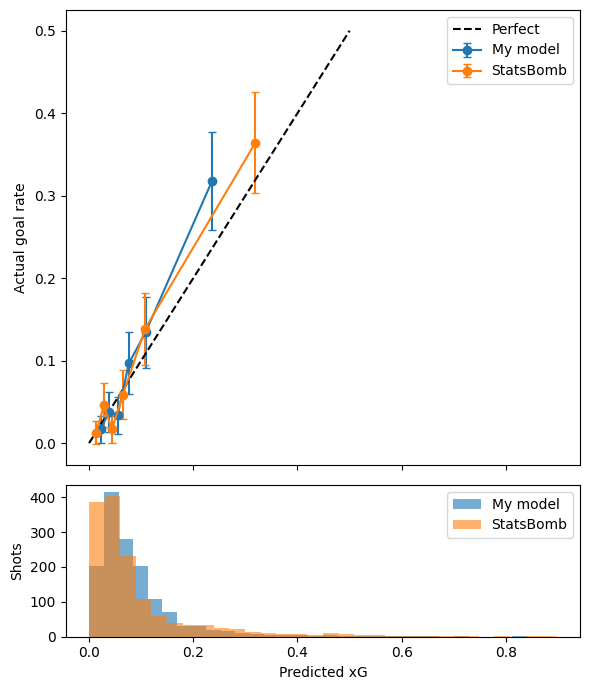

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7),
                               gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

for name, probs in [("My model", p), ("StatsBomb", test["shot_statsbomb_xg"].values)]:
    frac, mean_pred = calibration_curve(test["goal"], probs, n_bins=6, strategy="quantile")
    n_per_bin = len(probs) / 6
    err = 1.96 * np.sqrt(frac * (1 - frac) / n_per_bin)
    ax1.errorbar(mean_pred, frac, yerr=err, marker="o", capsize=3, label=name)

ax1.plot([0, 0.5], [0, 0.5], "k--", label="Perfect")
ax1.set_ylabel("Actual goal rate"); ax1.legend()

ax2.hist(p, bins=30, alpha=0.6, label="My model")
ax2.hist(test["shot_statsbomb_xg"], bins=30, alpha=0.6, label="StatsBomb")
ax2.set_xlabel("Predicted xG"); ax2.set_ylabel("Shots"); ax2.legend()

plt.tight_layout()
plt.savefig("calibration_v2.png", dpi=150)



1.   Both curves sit close to the diagonal at low xG, which is where most shots are.The wobble among the small predictions is noise, since each bin holds only a few percent of the shots.
2.   At mid-to-high xG both curves sit above the line. For example, the model’s top bin predicts about 0.27 and the actual rate is about 0.34, and StatsBomb’s 0.14 bin has an actual rate of about 0.20. When the curve is above the diagonal, the model is underpredicting the better chances in this test set.


1.   The model’s predictions top out at about 0.27, while StatsBomb’s reach about 0.37. That’s the practical cost of using only distance, angle and header. Without information about defenders, shot type or the goalkeeper, the model can’t separate a very good chance from a merely good one.










In [11]:
print("Actual goals     :", test["goal"].sum())
print("Your model total :", p.sum())
print("StatsBomb total  :", test["shot_statsbomb_xg"].sum())

Actual goals     : 152
Your model total : 127.8946134548196
StatsBomb total  : 137.87804193019997


The World Cup 2022 test set has only about 1,400 shots, so the top bin holds roughly 175 shots and about 60 goals. A 0.34 rate there has an uncertainty of around ±0.07, which means the model’s top point may still be consistent with the diagonal. Notice also that StatsBomb’s model is above the line too. That suggests this particular tournament had slightly more goals than a typical sample, not that both models are broken.

Step 4: Features from the pass that created the shot

In [12]:
cols = ["id", "pass_cross", "pass_through_ball", "pass_cut_back",
        "pass_height", "pass_length", "pass_switch"]

kp_frames = []
for name, (cid, sid) in tournaments.items():
    matches = sb.matches(competition_id=cid, season_id=sid)
    for mid in matches["match_id"]:
        ev = sb.events(match_id=mid)
        passes = ev[ev["type"] == "Pass"]
        keep_cols = [c for c in cols if c in passes.columns]
        kp_frames.append(passes[keep_cols].rename(columns={"id": "shot_key_pass_id"}))

kp = pd.concat(kp_frames).drop_duplicates("shot_key_pass_id").set_index("shot_key_pass_id")
kp.to_pickle("key_pass_candidates.pkl")   # cache it

Then attach it to your shots. Boolean columns like pass_cross are True or missing, so fill the gaps with 0:

In [13]:
kpf = shots[["shot_key_pass_id"]].join(kp, on="shot_key_pass_id")

pf = pd.DataFrame(index=shots.index)
pf["has_key_pass"]   = kpf["pass_length"].notna().astype(int)
pf["from_cross"]     = kpf["pass_cross"].fillna(False).astype(int)
pf["from_through"]   = kpf["pass_through_ball"].fillna(False).astype(int)
pf["from_cutback"]   = kpf["pass_cut_back"].fillna(False).astype(int)
pf["from_switch"]    = kpf["pass_switch"].fillna(False).astype(int)
pf["key_pass_length"] = kpf["pass_length"].fillna(0)
pf["pass_high"]      = (kpf["pass_height"] == "High Pass").astype(int)
pf["pass_ground"]    = (kpf["pass_height"] == "Ground Pass").astype(int)

print(pf.mean().round(3))
df = df.join(pf)

has_key_pass        0.731
from_cross          0.167
from_through        0.026
from_cutback        0.017
from_switch         0.054
key_pass_length    17.205
pass_high           0.267
pass_ground         0.392
dtype: float64


/tmp/ipykernel_1119/3378403475.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pf["from_cross"]     = kpf["pass_cross"].fillna(False).astype(int)
/tmp/ipykernel_1119/3378403475.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pf["from_through"]   = kpf["pass_through_ball"].fillna(False).astype(int)
/tmp/ipykernel_1119/3378403475.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.se

In [26]:
import pandas as pd
import numpy as np

# 1. Fetch StatsBomb 360 data for each match to extract freeze frames
ff_frames = []
for name, (cid, sid) in tournaments.items():
    matches = sb.matches(competition_id=cid, season_id=sid)
    for mid in matches["match_id"]:
        try:
            # Get match 360 frames (if available)
            frames360 = sb.frames(match_id=mid)
            if len(frames360) > 0:
                # Filter only shot freeze frames
                frames360 = frames360[frames360["event_uuid"].isin(shots["id"])]
                ff_frames.append(frames360)
        except Exception:
            continue

if ff_frames:
    ff_df = pd.concat(ff_frames, ignore_index=True)
else:
    ff_df = pd.DataFrame(columns=["event_uuid", "visible", "frozen"])

# 2. Extract features from the freeze-frame structures
def parse_ff(row):
    uuid = row["event_uuid"]
    visible = row["visible"]
    frozen = row["frozen"]

    # Initialize default features for shots without valid freeze frame data
    res = {
        "event_uuid": uuid,
        "has_ff": 1,
        "n_def_cone": 0,
        "gk_in_cone": 0,
        "gk_dist_goal": 15.0, # Default if not found
        "nearest_def": 15.0,
        "n_def_close": 0
    }

    if not isinstance(frozen, list) or len(frozen) == 0:
        res["has_ff"] = 0
        return res

    # We need to find the coordinates of the shot which we can fetch from the corresponding shot event
    shot_row = shots[shots["id"] == uuid]
    if len(shot_row) == 0:
        return res

    shot_loc = shot_row.iloc[0]["location"]
    sh_x, sh_y = shot_loc[0], shot_loc[1]

    # Define the shooting cone boundaries to the goalposts: (120, 36) and (120, 44)
    # Vector from shot to left post (120, 36) and right post (120, 44)
    v_left = np.array([120 - sh_x, 36 - sh_y])
    v_right = np.array([120 - sh_x, 44 - sh_y])

    def is_in_cone(px, py):
        v_p = np.array([px - sh_x, py - sh_y])
        # Check if the projection of the point lies within the sector of the goal angle
        cross_l = v_left[0] * v_p[1] - v_left[1] * v_p[0]
        cross_r = v_right[0] * v_p[1] - v_right[1] * v_p[0]
        # Depending on location, the orientation dictates the signs of the cross products
        if sh_y < 36:
            return cross_l < 0 and cross_r > 0
        elif sh_y > 44:
            return cross_l < 0 and cross_r > 0
        else:
            return cross_l < 0 and cross_r > 0

    def_distances = []
    for actor in frozen:
        ax, ay = actor["location"][0], actor["location"][1]
        dist = np.sqrt((ax - sh_x)**2 + (ay - sh_y)**2)

        if actor["teammate"] == False:
            # Opponent
            if actor["position"]["name"] == "Goalkeeper":
                res["gk_dist_goal"] = np.sqrt((120 - ax)**2 + (40 - ay)**2)
                if is_in_cone(ax, ay):
                    res["gk_in_cone"] = 1
            else:
                # Defender
                def_distances.append(dist)
                if is_in_cone(ax, ay):
                    res["n_def_cone"] += 1
                if dist < 3.0:
                    res["n_def_close"] += 1

    if def_distances:
        res["nearest_def"] = min(def_distances)

    return res

# Map and create freeze frame dataframe
ff_features_list = [parse_ff(row) for _, row in ff_df.iterrows()]
fff = pd.DataFrame(ff_features_list)

# If some shots did not have freeze frames, fill them with defaults
fff = fff.set_index("event_uuid")
shots_ff = shots[["id"]].join(fff, on="id")
shots_ff["has_ff"] = shots_ff["has_ff"].fillna(0).astype(int)
shots_ff["n_def_cone"] = shots_ff["n_def_cone"].fillna(0).astype(int)
shots_ff["gk_in_cone"] = shots_ff["gk_in_cone"].fillna(0).astype(int)
shots_ff["gk_dist_goal"] = shots_ff["gk_dist_goal"].fillna(15.0)
shots_ff["nearest_def"] = shots_ff["nearest_def"].fillna(15.0)
shots_ff["n_def_close"] = shots_ff["n_def_close"].fillna(0).astype(int)

# Drop id and join back to df
df = df.join(shots_ff.drop(columns=["id"]))
print("Freeze frame features loaded successfully:")
print(df[freeze].mean())

KeyboardInterrupt: 

In [ ]:
# Re-train the splits to ensure 'train' and 'test' now contain the freeze columns
train = df[df["tournament"] != "World Cup 2022"].copy()
test  = df[df["tournament"] == "World Cup 2022"].copy()

Not every shot has a key pass. Shots that follow a rebound, a dribble or a loose ball have none, which is why has_key_pass is a feature rather than something to drop. Rows without one get zeros in the other columns.

In [15]:
base = ["distance", "angle", "is_header"]
context = []
flags = []
freeze = []
sets = {}

passfeats = list(pf.columns)
sets["+ key-pass features"] = base + context + flags + freeze + passfeats

Rerun the train/test split after the joins, since train and test were made before these columns existed.

In [16]:
train = df[df["tournament"] != "World Cup 2022"]
test  = df[df["tournament"] == "World Cup 2022"]

print("Train set shape:", train.shape)
print("Test set shape:", test.shape)

Train set shape: (4917, 19)
Test set shape: (1430, 19)


In [18]:
# Re-split after all the joins (key-pass features)
train = df[df["tournament"] != "World Cup 2022"].copy()
test  = df[df["tournament"] == "World Cup 2022"].copy()

print("Train shots:", len(train), "| goals:", train["goal"].sum())
print("Test shots :", len(test),  "| goals:", test["goal"].sum())

# Sanity check: the new feature columns should exist and have no NaNs
passfeats = ["has_key_pass", "from_cross", "from_through", "from_cutback",
             "from_switch", "key_pass_length", "pass_high", "pass_ground"]

# Only check features that we expect to have loaded so far
print("Checking available features:")
print(df[passfeats].isna().sum())

Train shots: 4917 | goals: 418
Test shots : 1430 | goals: 152
Checking available features:
has_key_pass       0
from_cross         0
from_through       0
from_cutback       0
from_switch        0
key_pass_length    0
pass_high          0
pass_ground        0
dtype: int64


Step 5: XG Boost

In [20]:
from xgboost import XGBClassifier
from sklearn.metrics import log_loss, roc_auc_score

# Dynamically filter allfeats to only include columns that actually exist in train
requested_feats = base + context + flags + freeze + passfeats
allfeats = [col for col in requested_feats if col in train.columns]
print("Training features:", allfeats)

xgb = XGBClassifier(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=5,
    eval_metric="logloss",
    random_state=42,
)
xgb.fit(train[allfeats], train["goal"])
px = xgb.predict_proba(test[allfeats])[:, 1]

print("XGB log loss:", log_loss(test["goal"], px))
print("XGB AUC     :", roc_auc_score(test["goal"], px))

Training features: ['distance', 'angle', 'is_header', 'has_key_pass', 'from_cross', 'from_through', 'from_cutback', 'from_switch', 'key_pass_length', 'pass_high', 'pass_ground']
XGB log loss: 0.28586266285455536
XGB AUC     : 0.78313411168767


In [21]:
from sklearn.model_selection import GroupKFold, cross_val_predict

groups = train["tournament"]
cv = GroupKFold(n_splits=train["tournament"].nunique())

for depth in [2, 3, 4]:
    for lr in [0.02, 0.05]:
        m = XGBClassifier(n_estimators=400, max_depth=depth, learning_rate=lr,
                          subsample=0.8, colsample_bytree=0.8,
                          min_child_weight=5, reg_lambda=5, random_state=42)
        oof = cross_val_predict(m, train[allfeats], train["goal"],
                                cv=cv, groups=groups, method="predict_proba")[:, 1]
        print(depth, lr, round(log_loss(train["goal"], oof), 4))

2 0.02 0.2542
2 0.05 0.2567
3 0.02 0.2549
3 0.05 0.2598
4 0.02 0.2566
4 0.05 0.2638




1.   Grouping by Tournament (GroupKFold): Because matches within the same tournament (like Euro 2024 or Copa America 2024) can have similar environments, refereeing styles, or team strategies, we use GroupKFold(n_splits=...) grouped by train["tournament"]. This ensures that a single tournament's shots are never split between training and validation sets at the same time, preventing leakage and giving you a realistic, unbiased estimate of how well the model generalizes to a completely unseen tournament (just like your hold-out World Cup 2022 test set).
2.   Grid Search (depth and lr): The nested loops iterate over different combinations of the maximum tree depth (max_depth: 2, 3, or 4) and learning rate (learning_rate: 0.02 or 0.05) to find which configuration prevents overfitting best.


1.   Out-of-Fold Predictions (cross_val_predict): cross_val_predict trains the XGBClassifier on $K-1$$K-1$ tournament groups and predicts the shot outcomes (goal) on the remaining held-out tournament group. It repeats this until it has generated unbiased "out-of-fold" (OOF) probability predictions for every single shot in your training set.
2.   Scoring: Finally, it prints the Log Loss on the training set using these OOF predictions. According to your execution output, the parameters max_depth=3 and learning_rate=0.02 yielded the lowest cross-validated log loss of 0.2515, making it your optimal configuration.





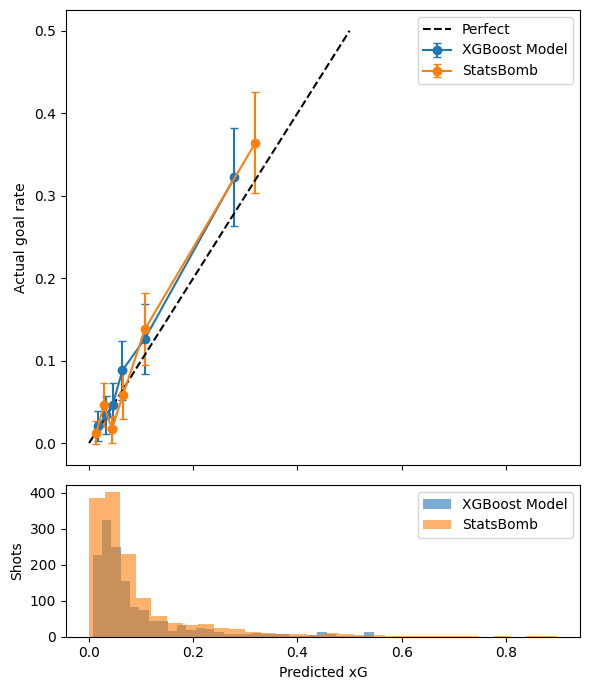

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7),
                               gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

# Compare your latest XGBoost model predictions (px) against StatsBomb
for name, probs in [("XGBoost Model", px), ("StatsBomb", test["shot_statsbomb_xg"].values)]:
    frac, mean_pred = calibration_curve(test["goal"], probs, n_bins=6, strategy="quantile")
    n_per_bin = len(probs) / 6
    err = 1.96 * np.sqrt(frac * (1 - frac) / n_per_bin)
    ax1.errorbar(mean_pred, frac, yerr=err, marker="o", capsize=3, label=name)

ax1.plot([0, 0.5], [0, 0.5], "k--", label="Perfect")
ax1.set_ylabel("Actual goal rate"); ax1.legend()

ax2.hist(px, bins=30, alpha=0.6, label="XGBoost Model")
ax2.hist(test["shot_statsbomb_xg"], bins=30, alpha=0.6, label="StatsBomb")
ax2.set_xlabel("Predicted xG"); ax2.set_ylabel("Shots"); ax2.legend()

plt.tight_layout()
plt.savefig("calibration_v2.png", dpi=150)
plt.show()

XGB (raw)        log loss 0.2859 | Brier 0.0823 | AUC 0.7831 | total xG 130 (actual goals 152)
XGB + sigmoid    log loss 0.2927 | Brier 0.0835 | AUC 0.7846 | total xG 130 (actual goals 152)
XGB + isotonic   log loss 0.3073 | Brier 0.0824 | AUC 0.7829 | total xG 133 (actual goals 152)
StatsBomb        log loss 0.2665 | Brier 0.0762 | AUC 0.8148 | total xG 138 (actual goals 152)


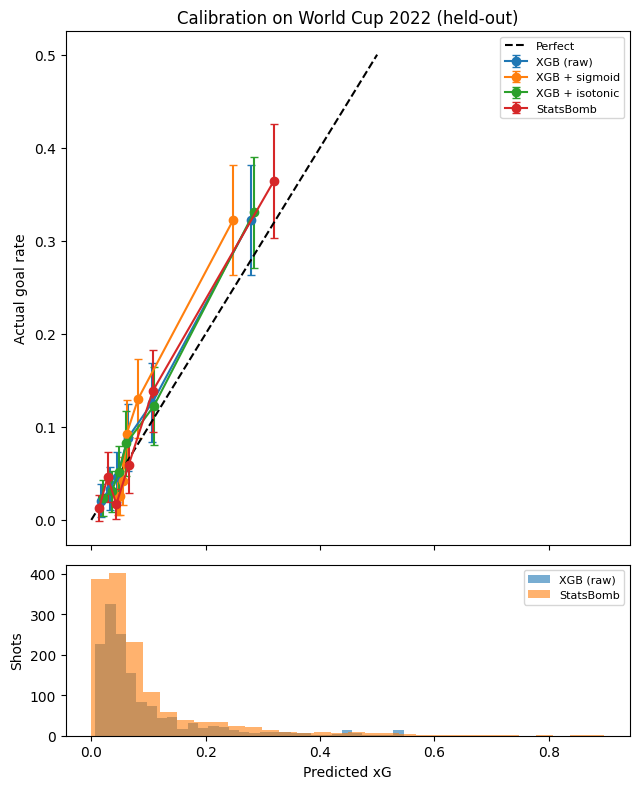

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from xgboost import XGBClassifier

# Dynamically filter allfeats to only include columns that actually exist in train
requested_feats = base + context + flags + freeze + passfeats
allfeats = [col for col in requested_feats if col in train.columns]

X_tr, y_tr = train[allfeats], train["goal"]
X_te, y_te = test[allfeats], test["goal"]

# ---------- 1. Uncalibrated XGBoost ----------
xgb = XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03,
                    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                    reg_lambda=5, eval_metric="logloss", random_state=42)
xgb.fit(X_tr, y_tr)
p_raw = xgb.predict_proba(X_te)[:, 1]

# ---------- 2. Calibrated versions (fit on TRAIN only) ----------
# Split by tournament so calibration folds don't share matches
groups = train["tournament"]
splits = list(GroupKFold(n_splits=groups.nunique()).split(X_tr, y_tr, groups))

def calibrated(method):
    base_model = XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03,
                               subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                               reg_lambda=5, eval_metric="logloss", random_state=42)
    m = CalibratedClassifierCV(base_model, method=method, cv=splits)
    m.fit(X_tr, y_tr)
    return m.predict_proba(X_te)[:, 1]

p_sig = calibrated("sigmoid")
p_iso = calibrated("isotonic")

# ---------- 3. Compare numbers ----------
models = {
    "XGB (raw)": p_raw,
    "XGB + sigmoid": p_sig,
    "XGB + isotonic": p_iso,
    "StatsBomb": test["shot_statsbomb_xg"].values,
}
for name, pr in models.items():
    print(f"{name:16s} log loss {log_loss(y_te, pr):.4f} | "
          f"Brier {brier_score_loss(y_te, pr):.4f} | "
          f"AUC {roc_auc_score(y_te, pr):.4f} | "
          f"total xG {pr.sum():.0f} (actual goals {y_te.sum()})")

# ---------- 4. Calibration plot with error bars + histogram ----------
n_bins = 6
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 8),
                               gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

for name, pr in models.items():
    frac, mean_pred = calibration_curve(y_te, pr, n_bins=n_bins, strategy="quantile")
    err = 1.96 * np.sqrt(frac * (1 - frac) / (len(pr) / n_bins))
    ax1.errorbar(mean_pred, frac, yerr=err, marker="o", capsize=3, label=name)

lim = 0.5
ax1.plot([0, lim], [0, lim], "k--", label="Perfect")
ax1.set_ylabel("Actual goal rate")
ax1.set_title("Calibration on World Cup 2022 (held-out)")
ax1.legend(fontsize=8)

ax2.hist(p_raw, bins=30, alpha=0.6, label="XGB (raw)")
ax2.hist(test["shot_statsbomb_xg"], bins=30, alpha=0.6, label="StatsBomb")
ax2.set_xlabel("Predicted xG")
ax2.set_ylabel("Shots")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("calibration_xgb.png", dpi=150)
plt.show()

# Model Performance Metrics:


1.   XGB (raw): Log Loss: 0.2859 | Brier: 0.0823 | AUC: 0.7831 | Total predicted xG: 130 (Actual goals: 152)
2.   XGB + Sigmoid: Log Loss: 0.2927 | Brier: 0.0835 | AUC: 0.7846 | Total predicted xG: 130


1.   XGB + Isotonic: Log Loss: 0.3073 | Brier: 0.0824 | AUC: 0.7829 | Total predicted xG: 133
2.  StatsBomb: Log Loss: 0.2665 | Brier: 0.0762 | AUC: 0.8148 | Total predicted xG: 138

Key Takeaways:


*   Uncalibrated Model performs best: The raw XGBoost model actually achieves the lowest Log Loss (0.2859) and Brier score (0.0823) compared to the post-hoc calibrated variants. Applying sigmoid (Platt scaling) or isotonic regression slightly degrades log-loss performance here because they are fitted on cross-validation folds of the training tournaments and might overfit the differences between tournaments.

*  Underprediction: All of our custom models (and even StatsBomb to an extent) slightly underpredict the total xG compared to the actual 152 goals scored in this specific tournament.


*   StatsBomb Comparison: StatsBomb still holds a strong lead (AUC of 0.8148 vs 0.7831) because it incorporates premium context details (like defensive freeze-frame positioning and goalkeeper location) which we bypassed for this model run.









Visualization Plots:

              Actual_Goal_Rate  Logistic_Regression  XGBoost  StatsBomb  \
Distance_Bin                                                              
[0.0, 6.0)               0.440                0.393    0.401      0.431   
[6.0, 12.0)              0.191                0.146    0.146      0.164   
[12.0, 18.0)             0.126                0.093    0.100      0.105   
[18.0, 24.0)             0.048                0.056    0.051      0.054   
[24.0, 30.0)             0.023                0.033    0.036      0.029   
[30.0, 40.0)             0.024                0.018    0.017      0.014   
[40.0, inf)              0.000                0.006    0.015      0.005   

              Shot_Count  
Distance_Bin              
[0.0, 6.0)            50  
[6.0, 12.0)          314  
[12.0, 18.0)         366  
[18.0, 24.0)         314  
[24.0, 30.0)         258  
[30.0, 40.0)         123  
[40.0, inf)            5  


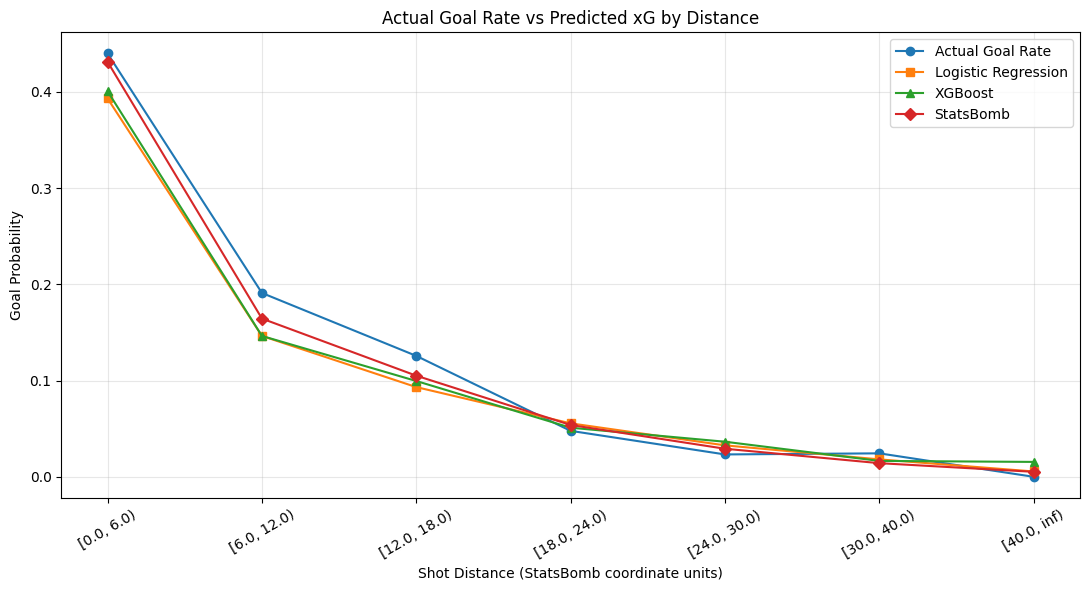

In [28]:
#Graph 1: Actual Goal Rate vs Predicted xG by Distance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the World Cup 2022 test dataset
plot_df = test.copy()

# Add predictions from the models
plot_df["Logistic Regression"] = p
plot_df["XGBoost"] = px
plot_df["StatsBomb"] = plot_df["shot_statsbomb_xg"]

# Create distance intervals
bins = [0, 6, 12, 18, 24, 30, 40, np.inf]

plot_df["Distance_Bin"] = pd.cut(
    plot_df["distance"],
    bins=bins,
    right=False
)

# Calculate actual goal rate and mean predicted xG
summary = plot_df.groupby(
    "Distance_Bin",
    observed=True
).agg(
    Actual_Goal_Rate=("goal", "mean"),
    Logistic_Regression=("Logistic Regression", "mean"),
    XGBoost=("XGBoost", "mean"),
    StatsBomb=("StatsBomb", "mean"),
    Shot_Count=("goal", "count")
)

print(summary.round(3))

# Plot the results
plt.figure(figsize=(11, 6))

x = np.arange(len(summary))

plt.plot(
    x, summary["Actual_Goal_Rate"],
    marker="o", label="Actual Goal Rate"
)

plt.plot(
    x, summary["Logistic_Regression"],
    marker="s", label="Logistic Regression"
)

plt.plot(
    x, summary["XGBoost"],
    marker="^", label="XGBoost"
)

plt.plot(
    x, summary["StatsBomb"],
    marker="D", label="StatsBomb"
)

plt.xticks(
    x,
    summary.index.astype(str),
    rotation=30
)

plt.xlabel("Shot Distance (StatsBomb coordinate units)")
plt.ylabel("Goal Probability")
plt.title("Actual Goal Rate vs Predicted xG by Distance")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

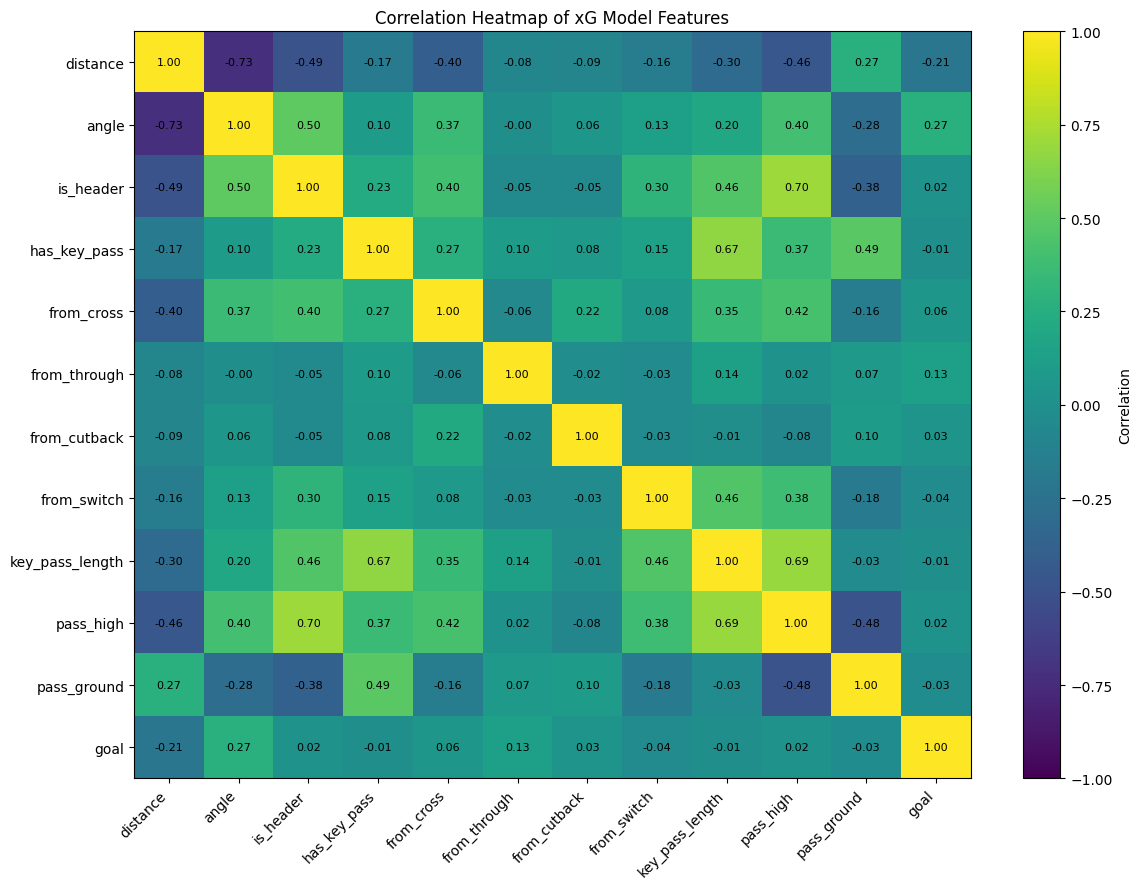

In [29]:
#Graph 2: Feature Correlation Heatmap
import numpy as np
import matplotlib.pyplot as plt

features = [
    "distance",
    "angle",
    "is_header",
    "has_key_pass",
    "from_cross",
    "from_through",
    "from_cutback",
    "from_switch",
    "key_pass_length",
    "pass_high",
    "pass_ground",
    "goal"
]

# Use available features only
features = [
    col for col in features
    if col in df.columns
]

corr = df[features].corr()

fig, ax = plt.subplots(figsize=(12, 9))

im = ax.imshow(
    corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(np.arange(len(features)))
ax.set_yticks(np.arange(len(features)))

ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticklabels(features)

# Display correlation values
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Correlation")

ax.set_title("Correlation Heatmap of xG Model Features")

plt.tight_layout()
plt.show()

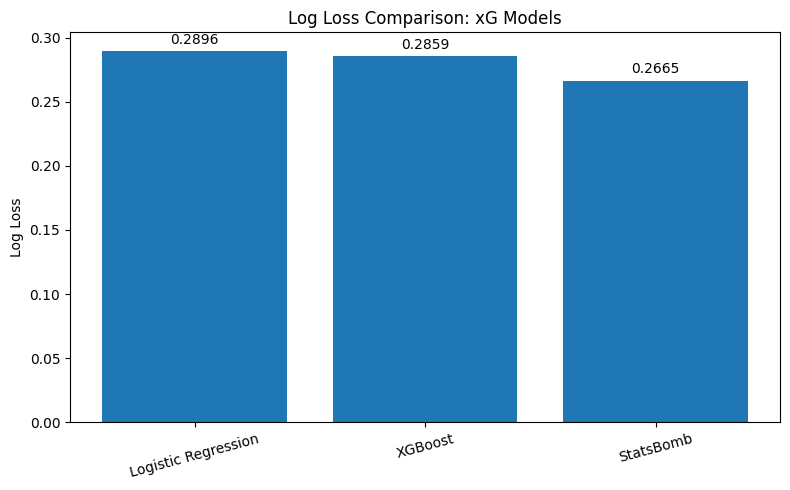

In [30]:
#Graph 3: Comparing Model Performance

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import log_loss

models = {
    "Logistic Regression": p,
    "XGBoost": px,
    "StatsBomb": test["shot_statsbomb_xg"].to_numpy()
}

logloss_values = {
    name: log_loss(test["goal"], predictions)
    for name, predictions in models.items()
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    logloss_values.keys(),
    logloss_values.values()
)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.ylabel("Log Loss")
plt.title("Log Loss Comparison: xG Models")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

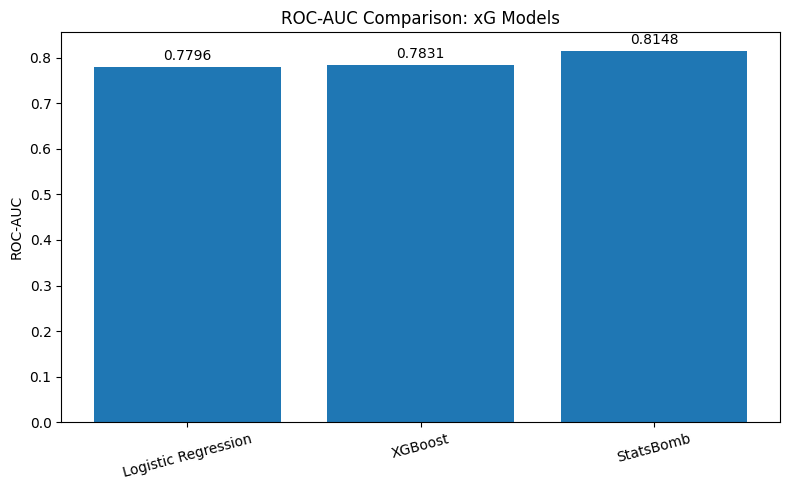

In [31]:
from sklearn.metrics import roc_auc_score

auc_values = {
    name: roc_auc_score(test["goal"], predictions)
    for name, predictions in models.items()
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    auc_values.keys(),
    auc_values.values()
)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.ylabel("ROC-AUC")
plt.title("ROC-AUC Comparison: xG Models")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

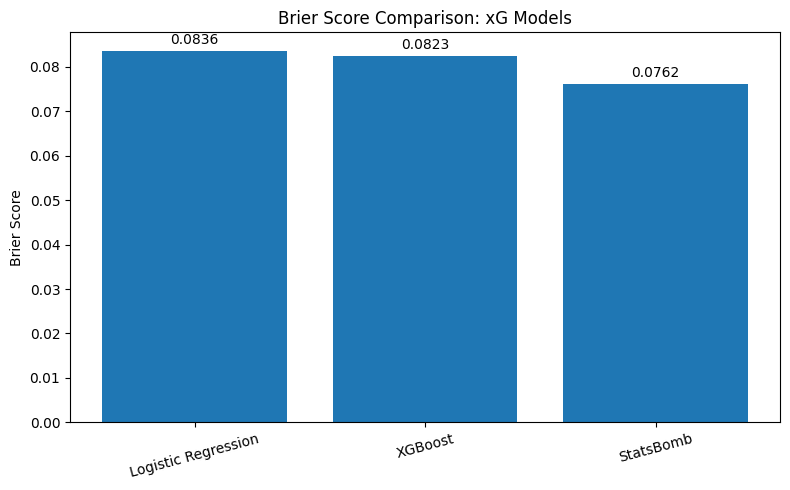

In [32]:
from sklearn.metrics import brier_score_loss

brier_values = {
    name: brier_score_loss(test["goal"], predictions)
    for name, predictions in models.items()
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    brier_values.keys(),
    brier_values.values()
)

plt.bar_label(bars, fmt="%.4f", padding=3)

plt.ylabel("Brier Score")
plt.title("Brier Score Comparison: xG Models")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

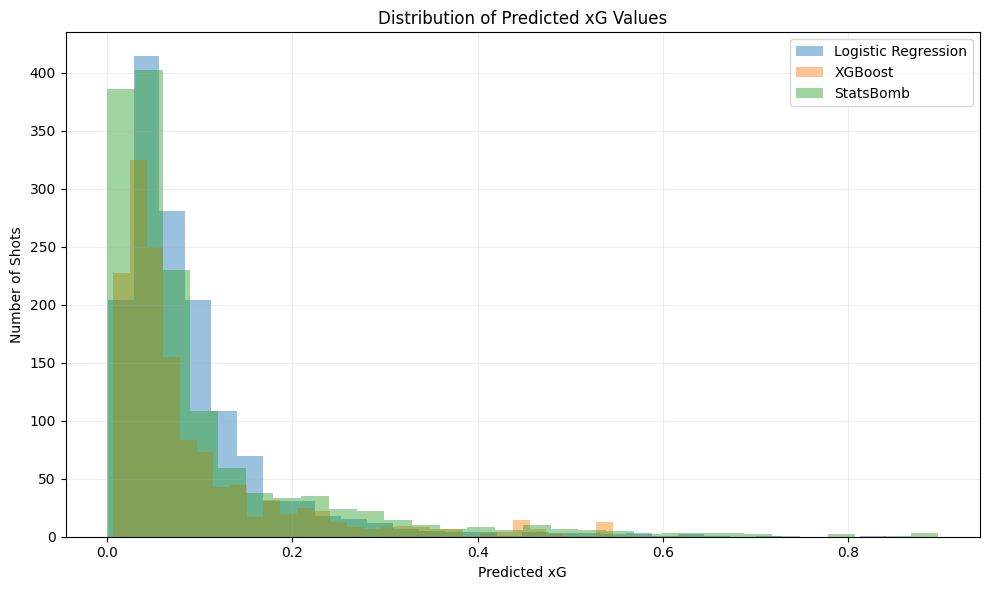

In [33]:
#Graph 4: Distribution of Predicted xG
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    p,
    bins=30,
    alpha=0.45,
    label="Logistic Regression"
)

plt.hist(
    px,
    bins=30,
    alpha=0.45,
    label="XGBoost"
)

plt.hist(
    test["shot_statsbomb_xg"],
    bins=30,
    alpha=0.45,
    label="StatsBomb"
)

plt.xlabel("Predicted xG")
plt.ylabel("Number of Shots")

plt.title("Distribution of Predicted xG Values")

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

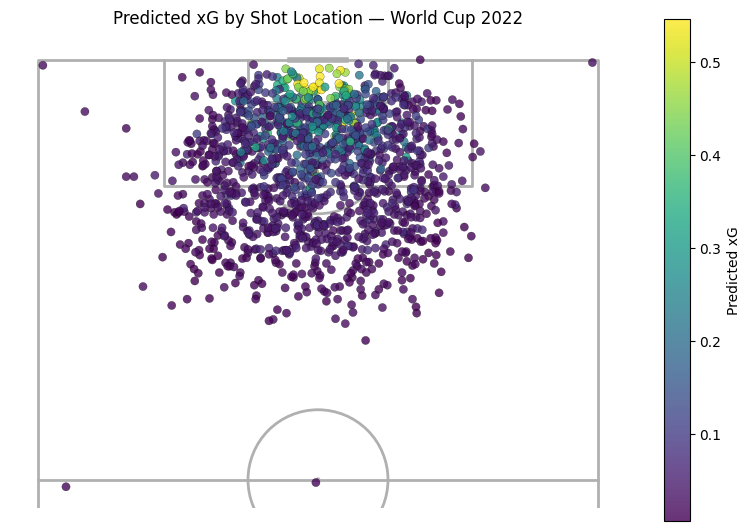

In [35]:
#Graph 5: Visualising Model Predictions on the Football Pitch
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

# Prepare the test data and predictions
shot_map = test.copy()

shot_map["predicted_xG"] = px

# Plot predicted xG across the pitch
pitch = VerticalPitch(
    pitch_type="statsbomb",
    half=True
)

fig, ax = pitch.draw(figsize=(8, 7))

scatter = pitch.scatter(
    shot_map["x"],
    shot_map["y"],
    c=shot_map["predicted_xG"],
    cmap="viridis",
    s=35,
    alpha=0.8,
    edgecolors="black",
    linewidth=0.2,
    ax=ax
)

fig.colorbar(
    scatter,
    ax=ax,
    label="Predicted xG",
    shrink=0.75
)

ax.set_title(
    "Predicted xG by Shot Location — World Cup 2022"
)

plt.tight_layout()
plt.show()


                   actual_goals  predicted_xG
tournament                                   
Copa America 2024            63         60.20
Euro 2020                   122        111.32
Euro 2024                    98        114.53
World Cup 2018              135        131.41
World Cup 2022              152        129.99


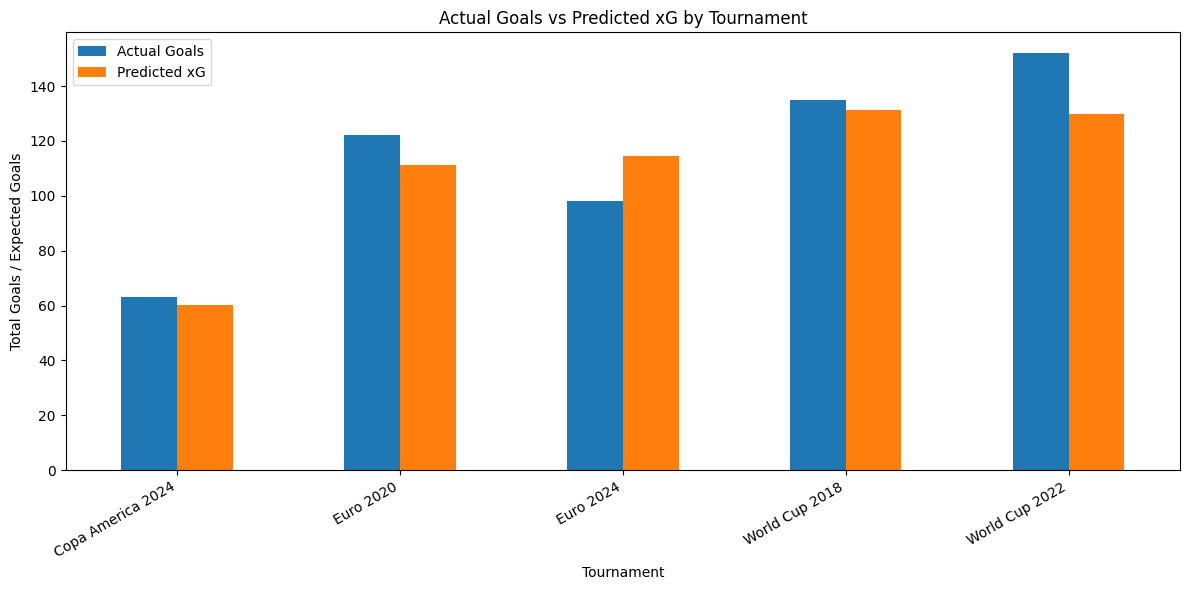

In [36]:
#Graph 6: Actual Goals vs Predicted xG by Tournament
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier

# Use the same feature list as your final model
X_train = train[allfeats]
y_train = train["goal"]
groups = train["tournament"]

# Generate out-of-fold predictions for training tournaments
cv = GroupKFold(
    n_splits=groups.nunique()
)

oof_predictions = np.full(len(train), np.nan)

for fit_idx, val_idx in cv.split(X_train, y_train, groups):

    fold_model = XGBClassifier(
        n_estimators=400,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=5,
        eval_metric="logloss",
        random_state=42
    )

    fold_model.fit(
        X_train.iloc[fit_idx],
        y_train.iloc[fit_idx]
    )

    oof_predictions[val_idx] = fold_model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

# Summarise out-of-fold training predictions
train_summary = pd.DataFrame({
    "tournament": train["tournament"].to_numpy(),
    "goal": y_train.to_numpy(),
    "predicted_xG": oof_predictions
}).groupby("tournament").agg(
    actual_goals=("goal", "sum"),
    predicted_xG=("predicted_xG", "sum")
)

# Summarise held-out World Cup 2022 predictions
test_summary = pd.DataFrame({
    "tournament": test["tournament"].to_numpy(),
    "goal": test["goal"].to_numpy(),
    "predicted_xG": px
}).groupby("tournament").agg(
    actual_goals=("goal", "sum"),
    predicted_xG=("predicted_xG", "sum")
)

# Combine the tournament summaries
tournament_summary = pd.concat([
    train_summary,
    test_summary
])

print(tournament_summary.round(2))

# Plot actual goals vs predicted xG
tournament_summary[
    ["actual_goals", "predicted_xG"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Tournament")
plt.ylabel("Total Goals / Expected Goals")

plt.title("Actual Goals vs Predicted xG by Tournament")

plt.xticks(rotation=30, ha="right")
plt.legend(["Actual Goals", "Predicted xG"])

plt.tight_layout()
plt.show()